Demand Forecasting Project

Step 1 : Import Libraries

In [3]:
# Standard imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Metrics & utilities
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

Step 2 : Load the DataSEt

In [5]:
df = pd.read_csv("Data.csv")
print("Shape :", df.shape)
df.head

Shape : (1048575, 5)


<bound method NDFrame.head of          Product_Code Warehouse Product_Category       Date Order_Demand
0        Product_0993    Whse_J     Category_028  2012/7/27         100 
1        Product_0979    Whse_J     Category_028  2012/1/19         500 
2        Product_0979    Whse_J     Category_028   2012/2/3         500 
3        Product_0979    Whse_J     Category_028   2012/2/9         500 
4        Product_0979    Whse_J     Category_028   2012/3/2         500 
...               ...       ...              ...        ...          ...
1048570  Product_1791    Whse_J     Category_006  2016/4/27        1000 
1048571  Product_1974    Whse_J     Category_006  2016/4/27           1 
1048572  Product_1787    Whse_J     Category_006  2016/4/28        2500 
1048573  Product_0901    Whse_J     Category_023  2016/10/7          50 
1048574  Product_0704    Whse_J     Category_001  2016/6/27           4 

[1048575 rows x 5 columns]>

Step 3 : Data Informatin

In [ ]:
# Dataset Overview
print("=" * 50)
print("DATASET INFORMATION")
print("=" * 50)

# Basic Information
print("\nDataset Info:")
display(df.info())

# Statistical Summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Missing Values Check
print("\n" + "=" * 50)
print("MISSING VALUES")
print("=" * 50)
display(df.isnull().sum())

# Duplicate Records Check
print("\n" + "=" * 50)
print("DUPLICATE ROWS")
print("=" * 50)
print("Total Duplicate Rows:", df.duplicated().sum())

DATASET INFORMATION

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype
---  ------            --------------    -----
 0   Product_Code      1048575 non-null  str  
 1   Warehouse         1048575 non-null  str  
 2   Product_Category  1048575 non-null  str  
 3   Date              1037336 non-null  str  
 4   Order_Demand      1048575 non-null  str  
dtypes: str(5)
memory usage: 83.0 MB


None


Statistical Summary:


,count,unique,top,freq
Product_Code,1048575,2160,Product_1359,16936
Warehouse,1048575,4,Whse_J,764447
Product_Category,1048575,33,Category_019,481099
Date,1037336,1729,2013/9/27,2075
Order_Demand,1048575,3828,1000,112682



MISSING VALUES


Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64


DUPLICATE ROWS
Total Duplicate Rows: 122423


Step 4 : Data Cleaning

In [7]:
# 1. Clean Date column 
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)

# 2. Clean Order_Demand (handle parentheses, strings, negatives)
df["Order_Demand"] = (
    df["Order_Demand"]
    .astype(str)                 
    .str.replace(r"[(),]", "", regex=True)  
    .str.strip()                
)

# Convert to numeric safely
df["Order_Demand"] = pd.to_numeric(df["Order_Demand"], errors="coerce")

# 3. Remove invalid rows (critical missing values only)
df = df.dropna(subset=["Date", "Order_Demand"])

# 4. Remove duplicates (after cleaning)
df = df.drop_duplicates()

# 5. Sort data by time (important for forecasting)
df = df.sort_values(by="Date")

# 6. Reset index after cleaning
df = df.reset_index(drop=True)



print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:\n", df.isnull().sum())
df.head()

Cleaned Dataset Shape: (922816, 5)

Missing Values After Cleaning:
 Product_Code        0
Warehouse           0
Product_Category    0
Date                0
Order_Demand        0
dtype: int64


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0965,Whse_A,Category_006,2011-01-08,2
1,Product_1724,Whse_A,Category_003,2011-05-31,108
2,Product_1521,Whse_S,Category_019,2011-06-24,85000
3,Product_1521,Whse_S,Category_019,2011-06-24,7000
4,Product_1507,Whse_C,Category_019,2011-09-02,1250


Step 5 :Exploratory Data Analysis

Dataset Shape: (922816, 5)


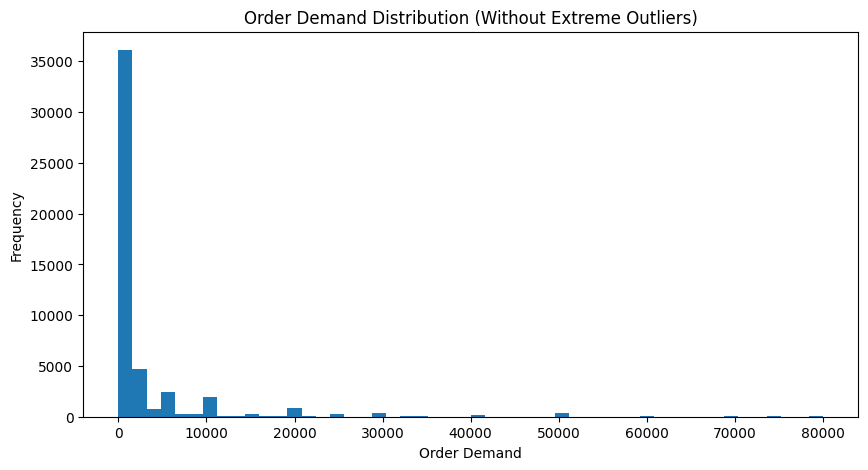

In [8]:
print("Dataset Shape:", df.shape)

# 1. Order Demand Distribution
plt.figure(figsize=(10, 5))

# Sample data for better performance and visualization
sample_data = df["Order_Demand"].sample(50000, random_state=42)

# Limit to 99th percentile to remove extreme outliers
upper_limit = sample_data.quantile(0.99)
sample_data = sample_data[sample_data <= upper_limit]

# Plot histogram
plt.hist(sample_data, bins=50)

# Titles and labels
plt.title("Order Demand Distribution (Without Extreme Outliers)")
plt.xlabel("Order Demand")
plt.ylabel("Frequency")

plt.show()

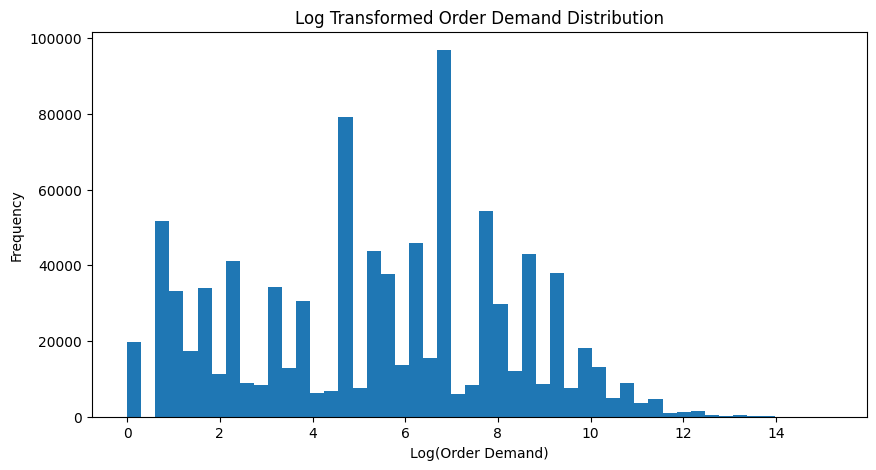

In [9]:
# 2. Log Transformation Plot

plt.figure(figsize=(10,5))
log_demand = np.log1p(df["Order_Demand"])
plt.hist(log_demand, bins=50)
plt.title("Log Transformed Order Demand Distribution")
plt.xlabel("Log(Order Demand)")
plt.ylabel("Frequency")
plt.show()


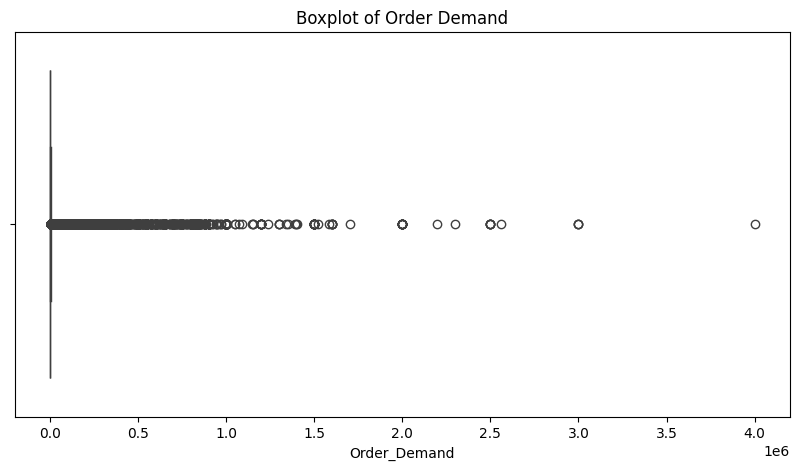

In [10]:
# 3. Boxplot for Outlier Detection

plt.figure(figsize=(10,5))
sns.boxplot(x=df["Order_Demand"])
plt.title("Boxplot of Order Demand")
plt.show()

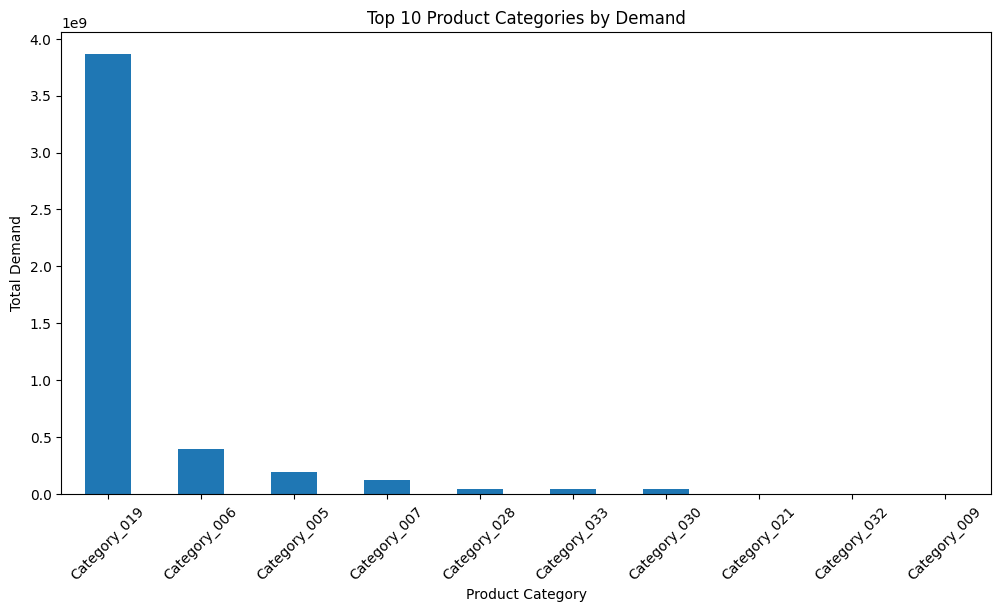

In [11]:
# 4. Product Category-wise Demand

category_demand = df.groupby("Product_Category")["Order_Demand"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))
category_demand.head(10).plot(kind="bar")
plt.title("Top 10 Product Categories by Demand")
plt.xlabel("Product Category")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.show()

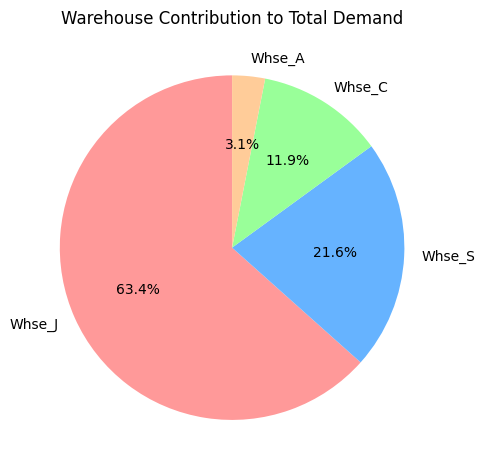

In [12]:
# 5. Pie Chart of Warehouse Share
warehouse_demand = df.groupby("Warehouse")["Order_Demand"].sum().sort_values(ascending=False)
plt.figure(figsize=(5,5))

warehouse_demand.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#ff9999","#66b3ff","#99ff99","#ffcc99"]
)

plt.title("Warehouse Contribution to Total Demand")
plt.ylabel("")
plt.tight_layout()
plt.show()

Invalid dates: 0
Invalid demand values: 0


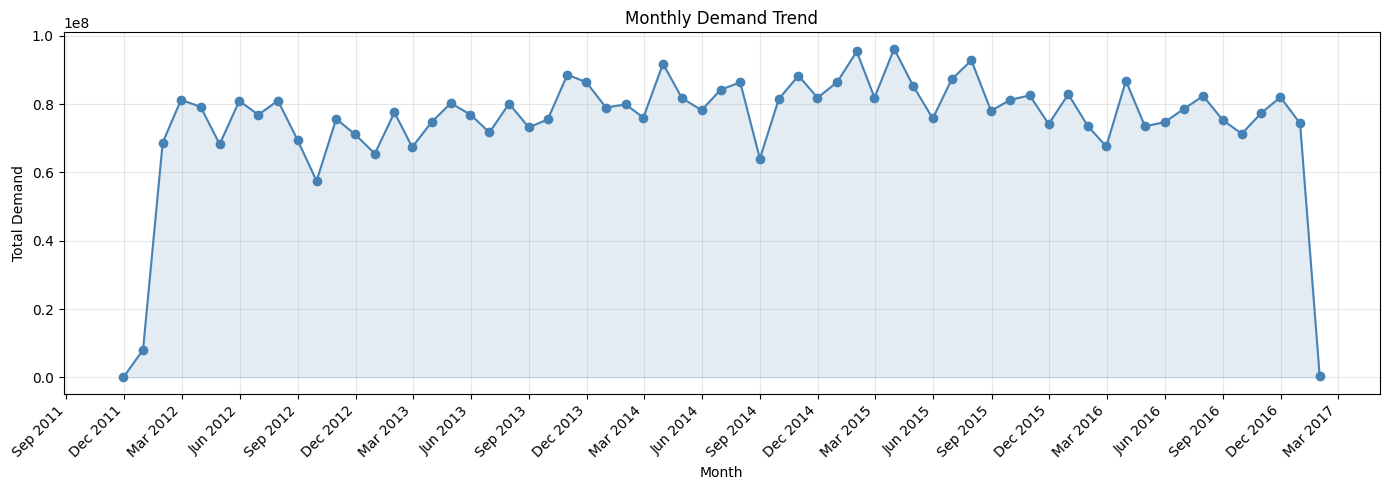

In [30]:
import matplotlib.dates as mdates

# Clean the target (handles "(100)" style negatives if it's stored as text)
if df["Order_Demand"].dtype == "object":
    df["Order_Demand"] = (
        df["Order_Demand"]
        .astype(str)
        .str.replace("(", "-", regex=False)
        .str.replace(")", "", regex=False)
    )
df["Order_Demand"] = pd.to_numeric(df["Order_Demand"], errors="coerce")

# Parse dates and see what was lost
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Invalid dates:", df["Date"].isna().sum())
print("Invalid demand values:", df["Order_Demand"].isna().sum())

# Monthly aggregation
monthly = df.dropna(subset=["Date"]).resample("ME", on="Date")["Order_Demand"].sum()

# Optional: drop the first/last month if they're incomplete
# monthly = monthly.iloc[1:-1]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly.index, monthly.values, marker="o", color="steelblue")
ax.fill_between(monthly.index, monthly.values, alpha=0.15, color="steelblue")

ax.set_title("Monthly Demand Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Total Demand")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("monthly_demand.png", dpi=300, bbox_inches="tight")
plt.show()

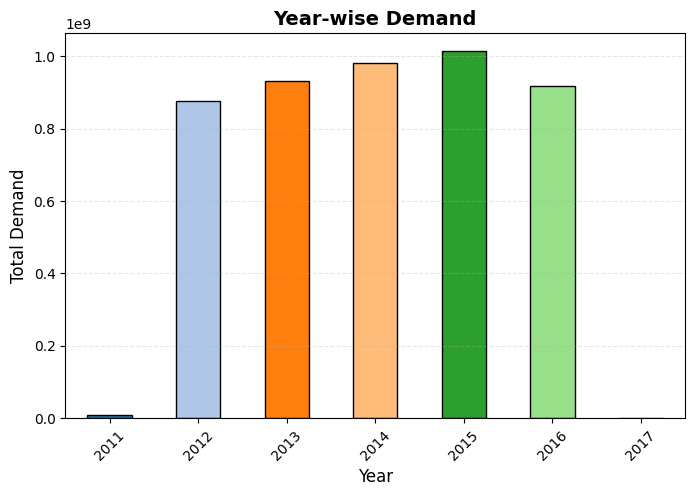

In [31]:
# 7. Year-wise Demand 

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Create Year column (FIX)
df["Year"] = df["Date"].dt.year

# Group by Year
yearly_demand = df.groupby("Year")["Order_Demand"].sum()

plt.figure(figsize=(8, 5))

# Distinct colors
colors = plt.cm.tab20(range(len(yearly_demand)))

yearly_demand.plot(
    kind="bar",
    color=colors,
    edgecolor="black"
)

plt.title("Year-wise Demand", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Demand", fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.savefig("year-wise_demand.png", dpi=300, bbox_inches="tight")
plt.show()

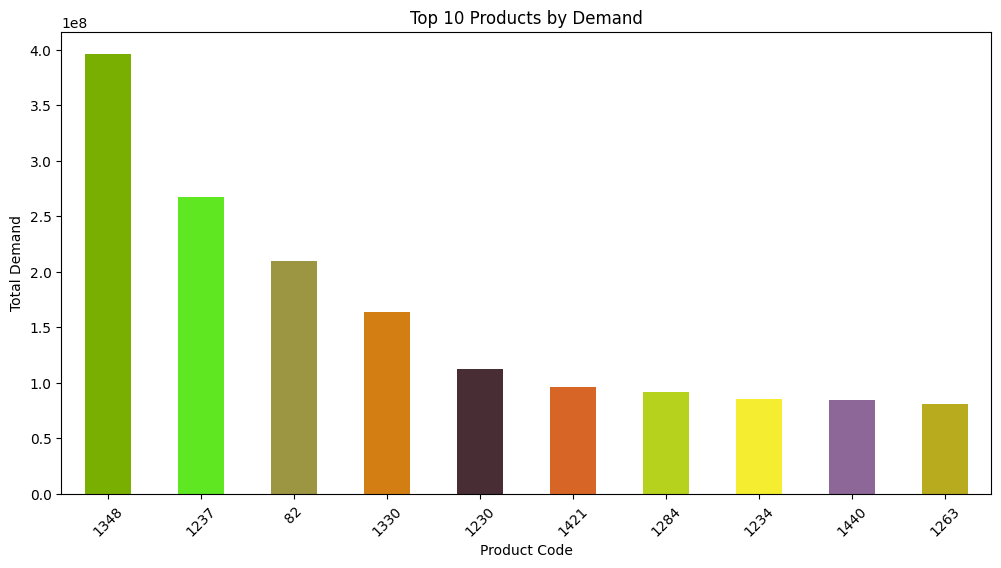

In [29]:
# 8. Top 10 Products by Demand

top_products = (
    df.groupby("Product_Code")["Order_Demand"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
colors = np.random.rand(len(top_products), 3)  

plt.figure(figsize=(12,6))
top_products.plot(kind="bar", color=colors)

plt.title("Top 10 Products by Demand")
plt.xlabel("Product Code")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.savefig("top_products.png", dpi=300, bbox_inches="tight")
plt.show()

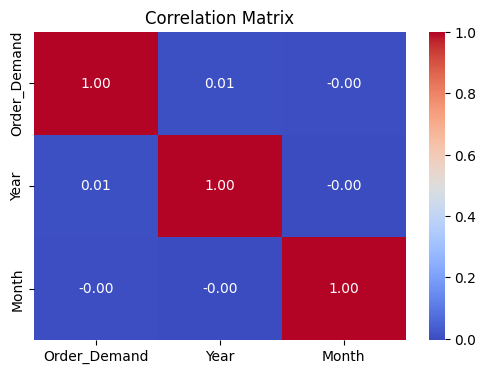

In [17]:
# 9. Correlation Matrix

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Create missing columns (FIX)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

# Select numeric data safely
numeric_df = df[["Order_Demand", "Year", "Month"]]

plt.figure(figsize=(6,4))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

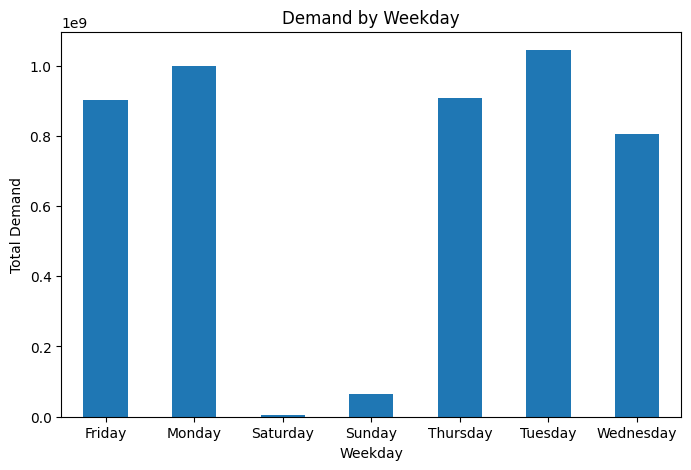

In [18]:
# 10. Demand by Weekday

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Weekday"] = df["Date"].dt.day_name()


weekday_demand = df.groupby("Weekday")["Order_Demand"].sum()

plt.figure(figsize=(8,5))
weekday_demand.plot(kind="bar")

plt.title("Demand by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Demand")

plt.xticks(rotation=0)
plt.show()

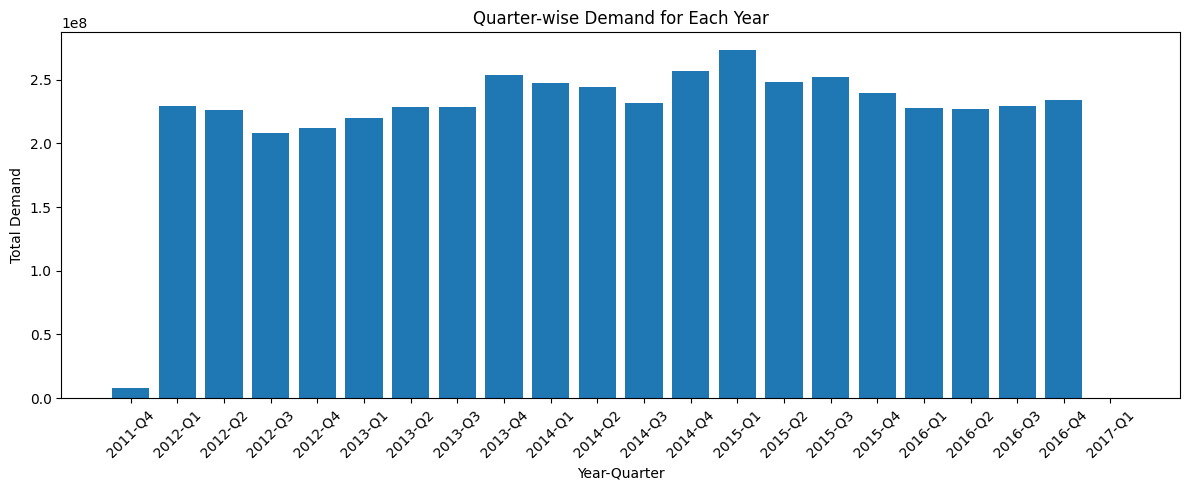

In [28]:
# 11. Quarter-wise Demand

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Year"] = df["Date"].dt.year
df["Quarter"] = "Q" + df["Date"].dt.quarter.astype(str)

quarter_year_demand = df.groupby(["Year", "Quarter"])["Order_Demand"].sum().reset_index()

# Create label for plotting
quarter_year_demand["Year_Quarter"] = quarter_year_demand["Year"].astype(str) + "-" + quarter_year_demand["Quarter"]

plt.figure(figsize=(12,5))
plt.bar(
    quarter_year_demand["Year_Quarter"],
    quarter_year_demand["Order_Demand"]
)

plt.title("Quarter-wise Demand for Each Year")
plt.xlabel("Year-Quarter")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("quarter-wise_Demand_yearwise.png", dpi=300, bbox_inches="tight")
plt.show()

Step 6 : Feature Engineering

In [20]:
df = df.sort_values("Date")

# Time-based features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Weekday"] = df["Date"].dt.weekday
df["Quarter"] = df["Date"].dt.quarter

# Cyclical encoding (IMPORTANT improvement)
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

df["Weekday_sin"] = np.sin(2 * np.pi * df["Weekday"] / 7)
df["Weekday_cos"] = np.cos(2 * np.pi * df["Weekday"] / 7)

# Lag features (CRITICAL for forecasting)
df["lag_1"] = df["Order_Demand"].shift(1)
df["lag_7"] = df["Order_Demand"].shift(7)
df["lag_30"] = df["Order_Demand"].shift(30)

# Rolling statistics
df["rolling_mean_7"] = df["Order_Demand"].rolling(7).mean()
df["rolling_std_7"] = df["Order_Demand"].rolling(7).std()

# Drop rows created by lagging
df = df.dropna().reset_index(drop=True)

Step 7 : Encoding Categorical Features

In [21]:
for col in ["Product_Code", "Warehouse", "Product_Category"]:
    df[col] = df[col].astype("category").cat.codes

Step 8 : Model Preparation

In [22]:
df = df.sort_values("Date")

split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
test = df.iloc[split_index:]

X_train = train.drop(columns=["Order_Demand", "Date"])
y_train = train["Order_Demand"]

X_test = test.drop(columns=["Order_Demand", "Date"])
y_test = test["Order_Demand"]

print(X_train.shape, X_test.shape)

(738228, 17) (184558, 17)


Step 9 : Multiple Machine Learning Models

In [24]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    predictions = model.predict(X_test)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, rmse, r2])

# Create results DataFrame
results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2 Score"]
)

# Sort by RMSE
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# Display results
print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(3))

# Best performing model
best_model_name = results_df.iloc[0]["Model"]

print("\nBest Performing Model:", best_model_name)

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Random Forest,3947.977,17067.646,0.717
1,XGBoost,4497.838,18174.468,0.679
2,Decision Tree,3995.959,19600.549,0.626
3,Linear Regression,7565.840,29203.002,0.171



Best Performing Model: Random Forest


Step 10 : Best Model Selection

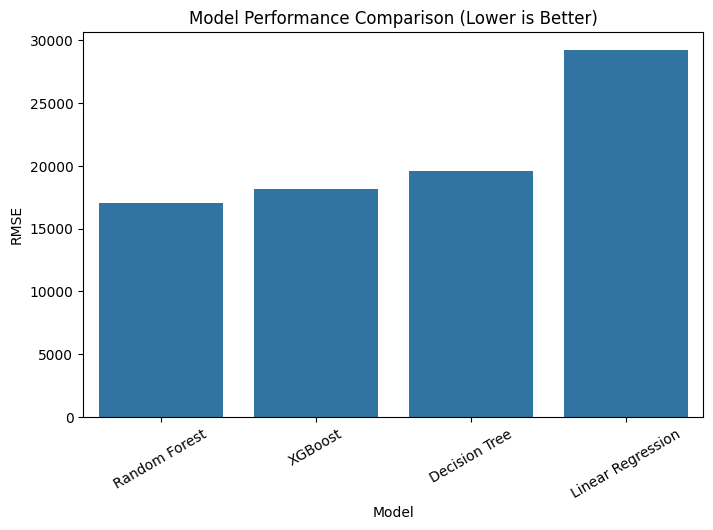

In [27]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Performance Comparison (Lower is Better)")
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.xticks(rotation=30)
plt.show()

In [26]:
# Save Best Model Automatically

import joblib

# Get best model name from results table (lowest RMSE)
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

# Get the already trained best model from models dictionary
best_model = models[best_model_name]

# Save the model
joblib.dump(best_model, "best_demand_forecasting_model.pkl")

print("Best model saved successfully as 'best_demand_forecasting_model.pkl'")

Best Model: Random Forest
Best model saved successfully as 'best_demand_forecasting_model.pkl'
